# Does the 2008 Liquidity-Credit Link Repeat?
**CFM301 Project 4: 2008, COVID and the 2022-23 rate shock**

**Research question:** "Is 2008’s near perfect link between liquidity and credit spreads a one-off, or does it repeat in March 2020 COVID and the 2022–23 rate shock?"

**Audience:** Central bank policymakers assessing whether a crisis-era liquidity indicator remains informative across different stress episodes.

Run all cells in order from this folder. The five supplied data files are the only numerical inputs. The main measures remain Baa minus 20-year TNC Treasury yields (percentage points) and the 10-year TNC off-minus-on Treasury premium (basis points). We retain the lecture replication and longest-sample extension, then compare the three episodes directly. No downloads, credentials or manual edits are required.

## 1. Economic motivation and episode comparison design

Corporate credit spreads compensate investors for expected default losses, risk premiums and other bond features. In the Merton model, risky corporate debt equals a safe bond minus a put on firm assets. Higher asset volatility tends to widen credit spreads. VIX provides a broad, imperfect indicator of these default-related conditions.

The newest Treasury can be more valuable because it is easier to trade or finance. A lower on-the-run yield makes the off-minus-on yield gap positive. That relative-value gap is a liquidity **proxy**, not a complete measure of Treasury or corporate market functioning. During different shocks, market-wide funding needs, default concerns and interest rates may affect these measures differently.

**Hypothesis:** If 2008's relationship is a recurring crisis pattern, later episodes should show similarly strong positive liquidity-credit co-movement. We examine levels, monthly changes and the liquidity association conditional on VIX. We do not impose a correlation threshold or choose windows to maximize the result.

**Main comparison:** Use three nonoverlapping **24-month windows**: January 2008-December 2009, January 2020-December 2021, and January 2022-December 2023. Each contains an important shock and subsequent adjustment. These windows equalize sample size but do not make the economic phases identical. The 2006-2009 lecture window remains a separate replication benchmark. Calendar-year and six-month windows test how the comparison depends on the chosen horizon.

**March 2020:** A single monthly observation cannot define a time-series correlation. We show its change from February explicitly, and estimate correlations over surrounding windows. The monthly Treasury files cannot recover a daily March event study, even though VIX itself is daily.

**Rates versus credit:** Rising corporate yields in 2022-23 need not mean rising credit spreads if Treasury yields also rise. We show both yield components and their difference. The period also contains banking stress in March 2023, so it is not a pure experiment isolating rate changes. Context: [Federal Reserve March 2022 policy statement](https://www.federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm) and [May 2023 Financial Stability Report](https://www.federalreserve.gov/publications/2023-may-financial-stability-report-asset-valuations.htm).

**Interpretation:** Results are descriptive associations. A different correlation can reflect a different shock, proxy performance, averaging, policy responses or sampling variation. It does not identify a causal liquidity effect or establish that 2008 is unique among every historical crisis.

## 2. Imports and local source files

The implementation follows the earlier projects: numbered Markdown sections, short pandas calculations, a cleaning log, displayed tables, matplotlib figures and statsmodels regressions. The raw files stay unchanged. `xlrd` is needed because the Treasury workbooks are genuine legacy `.xls` files.

| Local file | Source and meaning | Native frequency and units |
|---|---|---|
| `BAA.csv` | Moody's seasoned Baa corporate yield, distributed through FRED | Monthly yield, percent per year |
| `GS10.csv` | Federal Reserve H.15 10-year constant-maturity Treasury yield, FRED | Monthly business-day average, percent per year |
| `VIXCLS.csv` | Cboe VIX daily close, FRED | Daily index points |
| `tnc_qh_pars_1.xls` | US Treasury TNC fitted par yield curve | Monthly average par yields, percent per year |
| `tnc_qh_otrpars.xls` | US Treasury TNC fitted on-the-run par yields | Monthly average par yields, percent per year |

The assignment PDF and `Ch 9 Bonds.pptx` are reading materials, not numerical inputs to the estimates. PowerPoint's presentation order correctly places the Merton discussion on slides 48-50, VIX on 51, the two puzzles on 54-55, and liquidity on 59. Internal XML filenames use a different order. Sources and methodology links appear in Section 11 for reference only.

In [1]:
from pathlib import Path
import sys
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

%matplotlib inline

DATA = Path('data')
AS_OF = pd.Timestamp('2026-11-06')  # Fixed inspection date for this supplied data vintage.
ORIGINAL_START, ORIGINAL_END = '2006-01', '2009-09'
# Fixed comparison windows, anchors and sensitivities are declared before estimation.
EPISODES = {
    'GFC 2008-09': ('2008-01', '2009-12'),
    'COVID 2020-21': ('2020-01', '2021-12'),
    'Rate shock 2022-23': ('2022-01', '2023-12')
}
ANCHORS = {'GFC 2008-09': '2008-09', 'COVID 2020-21': '2020-03',
           'Rate shock 2022-23': '2022-03'}
YEAR_WINDOWS = {'Calendar 2008': ('2008-01', '2008-12'),
                'Calendar 2020': ('2020-01', '2020-12'),
                'Calendar 2022': ('2022-01', '2022-12'),
                'Calendar 2023': ('2023-01', '2023-12')}
ACUTE_WINDOWS = {'GFC Sep 2008-Feb 2009': ('2008-09', '2009-02'),
                 'COVID Mar-Aug 2020': ('2020-03', '2020-08'),
                 'Rates Mar-Aug 2022': ('2022-03', '2022-08')}

pd.set_option('display.max_colwidth', 95)
pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 10,
                     'axes.spines.top': False, 'axes.grid': True, 'grid.alpha': 0.2})

versions = pd.Series({name: metadata.version(name) for name in
                      ['pandas', 'numpy', 'matplotlib', 'statsmodels', 'scipy', 'xlrd',
                       'ipython', 'ipykernel', 'nbformat', 'nbclient', 'nbconvert']}, name='Version')
print('Python:', sys.version.split()[0])
display(versions.to_frame())

raw_csv = {name: pd.read_csv(DATA / f'{name}.csv', na_values=['.'])
           for name in ['BAA', 'GS10', 'VIXCLS']}
treasury_files = {'TNC off-the-run': 'tnc_qh_pars_1.xls',
                  'TNC on-the-run': 'tnc_qh_otrpars.xls'}
raw_xls = {}
sheet_rows = []
for name, filename in treasury_files.items():
    sheets = pd.read_excel(DATA / filename, sheet_name=None, header=None, engine='xlrd')
    raw_xls[name] = sheets['Sheet1']
    for sheet_name, frame in sheets.items():
        sheet_rows.append({'File': filename, 'Sheet': sheet_name,
                           'Rows': len(frame), 'Columns': len(frame.columns)})
display(pd.DataFrame(sheet_rows))

Python: 3.14.6


,Version
pandas,3.0.5
numpy,2.5.1
matplotlib,3.11.1
statsmodels,0.14.6
scipy,1.18.0
xlrd,2.0.2
ipython,9.15.0
ipykernel,6.31.0
nbformat,5.10.4
nbclient,0.11.0


,File,Sheet,Rows,Columns
0,tnc_qh_pars_1.xls,Sheet1,615,9
1,tnc_qh_pars_1.xls,Sheet2,0,0
2,tnc_qh_pars_1.xls,Sheet3,0,0
3,tnc_qh_otrpars.xls,Sheet1,495,5
4,tnc_qh_otrpars.xls,Sheet2,0,0
5,tnc_qh_otrpars.xls,Sheet3,0,0


### 2.1 Inspect the files before selecting columns

The CSVs use `observation_date` in ISO `YYYY-MM-DD` format. Each Treasury `Sheet1` has six heading/spacer rows, a blank second column, maturity labels in row 5, and dates such as `Jan 1976`. Sheets 2 and 3 are empty. The previews below expose the titles, units, available maturities, original dtypes and first/last records.

In [2]:
for name, frame in raw_csv.items():
    print(f'\n{name}: {frame.shape}; columns = {frame.columns.tolist()}')
    display(frame.dtypes.astype(str).to_frame('Original dtype'))
    display(pd.concat([frame.head(3), frame.tail(3)]))

for name, frame in raw_xls.items():
    print(f'\n{name}: {frame.shape}; header and sample records')
    display(frame.head(9))
    display(frame.tail(3))


BAA: (1294, 2); columns = ['observation_date', 'BAA']


,Original dtype
observation_date,str
BAA,float64


,observation_date,BAA
0,1919-01-01,7.12
1,1919-02-01,7.20
2,1919-03-01,7.15
1291,2026-08-01,6.32
1292,2026-09-01,6.47
1293,2026-10-01,6.59



GS10: (883, 2); columns = ['observation_date', 'GS10']


,Original dtype
observation_date,str
GS10,float64


,observation_date,GS10
0,1953-04-01,2.83
1,1953-05-01,3.05
2,1953-06-01,3.11
880,2026-08-01,4.68
881,2026-09-01,4.99
882,2026-10-01,5.13


... (5 outputs left out)

,0,1,2,3,4,5,6,7,8
612,Jul 2026,NaN,4.23,4.27,4.34,4.44,4.61,5.11,5.11
613,Aug 2026,NaN,4.23,4.3,4.4,4.51,4.7,5.22,5.23
614,Sep 2026,NaN,4.66,4.75,4.82,4.88,4.99,5.39,5.37



TNC on-the-run: (495, 5); header and sample records


,0,1,2,3,4
0,The Treasury Nominal Coupon-Issue (TNC) Yield Curve,NaN,NaN,NaN,NaN
1,"Monthly Average On-the-Run Par Yields, Percent",NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,Date,NaN,Maturity,NaN,NaN
4,NaN,NaN,2 Years,5 Years,10 Years
5,NaN,NaN,NaN,NaN,NaN
6,Jan 1986,NaN,8.15,8.67,9.19
7,Feb 1986,NaN,8,8.34,8.73
8,Mar 1986,NaN,7.23,7.48,7.78


,0,1,2,3,4
492,Jul 2026,NaN,4.22,4.33,4.6
493,Aug 2026,NaN,4.22,4.39,4.69
494,Sep 2026,NaN,4.66,4.8,4.99


## 3. Cleaning and monthly alignment

**Rules applied before estimation:**

- Remove only completely identical records, reporting the count. If different records share a date, stop and display them rather than pick a value.
- Parse the documented date formats explicitly. Unexpected dates or nonnumeric entries cause an error. Existing blank/`.` values stay missing.
- Use the monthly BAA, GS10 and Treasury averages as supplied. Average the available daily VIX closes within each calendar month and show the number of contributing days. Holiday blanks are excluded from that mean, without forward filling. Weekends are not expected trading observations.
- Exclude an unfinished calendar month using the fixed inspection date above. In this vintage, November 2026 has only four VIX observations. No complete-case analysis may quietly treat that as a full month.
- Flag observations more than four sample standard deviations from their series mean for inspection. Retain genuine stress observations, negative fitted liquidity premiums and zero premiums. No trimming or winsorization is applied.

The log's `affected` column refers to the explicitly named object (rows, cells, or months). Diagnostic rows do not necessarily remove observations.

In [3]:
cleaning_log = []

def log_step(dataset, step, affected, remaining, note=''):
    cleaning_log.append({'dataset': dataset, 'step': step, 'affected': int(affected),
                         'remaining_rows': int(remaining), 'note': note})

def clean_frame(frame, name, date_format):
    # All value columns are retained here, so duplicate checks do not hide conflicts.
    frame = frame.copy()
    n = len(frame)
    frame = frame.drop_duplicates()
    log_step(name, 'Exact duplicate rows removed', n - len(frame), len(frame))

    dates = pd.to_datetime(frame['date'], format=date_format, errors='coerce')
    log_step(name, 'Invalid dates (stop if nonzero)', dates.isna().sum(), len(frame))
    assert dates.notna().all(), f'Inspect invalid dates in {name}'
    frame['date'] = dates
    columns = frame.columns.drop('date')
    for column in columns:
        converted = pd.to_numeric(frame[column], errors='coerce')
        bad = frame[column].notna() & converted.isna()
        log_step(name, f'{column}: unexpected nonnumeric cells', bad.sum(), len(frame))
        assert not bad.any(), f'Unexpected entries in {name}: {frame.loc[bad, column]}'
        frame[column] = converted

    conflicts = frame['date'].duplicated(keep=False)
    log_step(name, 'Rows with conflicting duplicate dates (stop if nonzero)',
             conflicts.sum(), len(frame))
    if conflicts.any():
        display(frame.loc[conflicts])
        raise ValueError(f'Conflicting records in {name}; no automatic selection')
    log_step(name, 'Missing numeric cells retained', frame[columns].isna().sum().sum(), len(frame),
             'No imputation. Missing values are excluded only where an analysis requires them.')
    return frame.set_index('date').sort_index()

clean_csv = {}
for name, frame in raw_csv.items():
    assert frame.columns.tolist() == ['observation_date', name]
    clean_csv[name] = clean_frame(frame.rename(columns={'observation_date': 'date'}), name, '%Y-%m-%d')

treasury = {}
for name, frame in raw_xls.items():
    assert 'Monthly Average' in str(frame.iloc[1, 0]) and 'Percent' in str(frame.iloc[1, 0])
    assert frame.iloc[:, 1].isna().all(), 'Unexpected data in the spacer column'
    maturities = frame.iloc[4, 2:].tolist()
    expected = (['2 Years', '3 Years', '5 Years', '7 Years', '10 Years', '20 Years', '30 Years']
                if name == 'TNC off-the-run' else ['2 Years', '5 Years', '10 Years'])
    assert maturities == expected
    selected = frame.iloc[6:, [0] + list(range(2, len(frame.columns)))].copy()
    selected.columns = ['date'] + maturities
    log_step(name, 'Header/spacer rows excluded', 6, len(selected), 'Non-observation rows')
    treasury[name] = clean_frame(selected, name, '%b %Y')

display(pd.DataFrame(cleaning_log))

,dataset,step,affected,remaining_rows,note
0,BAA,Exact duplicate rows removed,0,1294,
1,BAA,Invalid dates (stop if nonzero),0,1294,
2,BAA,BAA: unexpected nonnumeric cells,0,1294,
3,BAA,Rows with conflicting duplicate dates (stop if nonzero),0,1294,
4,BAA,Missing numeric cells retained,0,1294,No imputation. Missing values are excluded only where an analysis requires them.
5,GS10,Exact duplicate rows removed,0,883,
6,GS10,Invalid dates (stop if nonzero),0,883,
7,GS10,GS10: unexpected nonnumeric cells,0,883,
8,GS10,Rows with conflicting duplicate dates (stop if nonzero),0,883,
9,GS10,Missing numeric cells retained,0,883,No imputation. Missing values are excluded only where an analysis requires them.


### 3.1 Monthly frequency, holiday gaps and source coverage

Monthly dates label calendar months, not the first trading day or an announcement date. VIX averages below use its observed daily closes, so different series' underlying business-day calendars need not coincide exactly. A missing daily value remains absent from the mean. An entirely unobserved month remains missing. No look-ahead or prediction claim is made because the analysis is contemporaneous.

In [4]:
monthly = {}
for name, frame in {**clean_csv, **treasury}.items():
    if name != 'VIXCLS':
        months = frame.index.to_period('M')
        assert not months.duplicated().any(), f'Multiple monthly records in {name}'
        out = frame.copy()
        out.index = months
        monthly[name] = out.reindex(pd.period_range(months.min(), months.max(), freq='M'))
        log_step(name, 'Absent calendar months inserted as missing',
                 len(monthly[name]) - len(out), len(monthly[name]))

vix_daily = clean_csv['VIXCLS']['VIXCLS']
weekday_dates = pd.date_range(vix_daily.index.min(), vix_daily.index.max(), freq='B')
display(pd.Series({'Daily source rows': len(vix_daily),
                   'Blank daily closes': vix_daily.isna().sum(),
                   'Weekday dates absent from file': len(weekday_dates.difference(vix_daily.index)),
                   'Weekend rows': (vix_daily.index.dayofweek >= 5).sum()}).to_frame('Count'))

vix_monthly = vix_daily.groupby(vix_daily.index.to_period('M')).agg(['mean', 'count', 'size'])
vix_monthly.columns = ['VIXCLS', 'valid_days', 'source_rows']
vix_monthly = vix_monthly.reindex(pd.period_range(vix_monthly.index.min(),
                                                vix_monthly.index.max(), freq='M'))
log_step('VIXCLS', 'Blank daily closes excluded from monthly means',
         vix_daily.isna().sum(), len(vix_monthly), 'Daily rows affected; no values filled')
print('VIX monthly aggregation: first and last three months')
display(pd.concat([vix_monthly.head(3), vix_monthly.tail(3)]).round(3))

unfinished = vix_monthly.index >= AS_OF.to_period('M')
log_step('VIXCLS', 'Unfinished/future calendar months excluded', unfinished.sum(),
         (~unfinished).sum(), f'As of {AS_OF.date()}; daily rows in these months: '
         f'{int(vix_monthly.loc[unfinished, "source_rows"].sum())}')
monthly['VIXCLS'] = vix_monthly.loc[~unfinished, ['VIXCLS']]

coverage_rows = []
for name, frame in monthly.items():
    good = frame.notna().all(axis=1)
    coverage_rows.append({'Series/file': name, 'Start': str(frame.index.min()),
                          'End': str(frame.index.max()), 'Calendar months': len(frame),
                          'Complete months': int(good.sum()), 'Incomplete months': int((~good).sum())})
coverage = pd.DataFrame(coverage_rows).set_index('Series/file')
display(coverage)
print('Monthly preparation audit')
display(pd.DataFrame(cleaning_log).iloc[-6:])

,Count
Daily source rows,9613
Blank daily closes,302
Weekday dates absent from file,0
Weekend rows,0


VIX monthly aggregation: first and last three months


,VIXCLS,valid_days,source_rows
1990-01,23.347,22,22
1990-02,23.263,19,20
1990-03,20.062,22,22
2026-09,15.775,22,22
2026-10,16.896,22,22
2026-11,21.692,4,4


,Start,End,Calendar months,Complete months,Incomplete months
Series/file,,,,,
BAA,1919-01,2026-10,1294,1294,0
GS10,1953-04,2026-10,883,883,0
TNC off-the-run,1976-01,2026-09,609,609,0
TNC on-the-run,1986-01,2026-09,489,489,0
VIXCLS,1990-01,2026-10,442,442,0


Monthly preparation audit


,dataset,step,affected,remaining_rows,note
35,BAA,Absent calendar months inserted as missing,0,1294,
36,GS10,Absent calendar months inserted as missing,0,883,
37,TNC off-the-run,Absent calendar months inserted as missing,0,609,
38,TNC on-the-run,Absent calendar months inserted as missing,0,489,
39,VIXCLS,Blank daily closes excluded from monthly means,302,443,Daily rows affected; no values filled
40,VIXCLS,Unfinished/future calendar months excluded,1,442,As of 2026-11-06; daily rows in these months: 4


In [5]:
display(Markdown(f'''**Coverage differs materially.** BAA spans {coverage.loc['BAA', 'Start']} to
{coverage.loc['BAA', 'End']}, GS10 {coverage.loc['GS10', 'Start']} to {coverage.loc['GS10', 'End']},
the fitted off-the-run curve {coverage.loc['TNC off-the-run', 'Start']} to
{coverage.loc['TNC off-the-run', 'End']}, and the on-the-run curve
{coverage.loc['TNC on-the-run', 'Start']} to {coverage.loc['TNC on-the-run', 'End']}.
Complete monthly VIX starts in {coverage.loc['VIXCLS', 'Start']} and ends in
{coverage.loc['VIXCLS', 'End']}. Thus the on-the-run file limits the two-spread chart's
starting date, while VIX further shortens the regression sample. The final Treasury
month limits the common ending date. Longer BAA/GS10 histories do not create earlier liquidity data.'''))

**Coverage differs materially.** BAA spans 1919-01 to
2026-10, GS10 1953-04 to 2026-10,
the fitted off-the-run curve 1976-01 to
2026-09, and the on-the-run curve
1986-01 to 2026-09.
Complete monthly VIX starts in 1990-01 and ends in
2026-10. Thus the on-the-run file limits the two-spread chart's
starting date, while VIX further shortens the regression sample. The final Treasury
month limits the common ending date. Longer BAA/GS10 histories do not create earlier liquidity data.

## 4. Credit and Treasury liquidity spread construction

### 4.1 Maturity matching and units

FRED's BAA definition states that its bonds have maturities **20 years and above**. GS10 is a 10-year constant-maturity rate. Consequently, `BAA - GS10` combines a corporate premium with differences in maturity, duration and the slope of the Treasury curve. It is a useful reference, but cannot be described as an exactly matched credit spread.

The main measure is **BAA minus the 20-year TNC par yield**. Twenty years is the lower bound of BAA's stated maturity range and is a closer available benchmark. The local data do not contain the corporate index's changing maturity weights, cash flows, duration or option adjustments, so an exact match is impossible. We also report the available 30-year benchmark in sensitivity analysis. Changing the benchmark changes both maturity and the Treasury yield construction relative to GS10.

All source yields are annual percentages. Therefore subtraction gives **percentage points (pp)** without multiplying by 100. For the Treasury liquidity proxy, multiplying that yield difference by 100 converts pp to **basis points (bp)**. One pp equals 100 bp. VIX remains in index points.

### 4.2 Is the Treasury difference defensible?

The workbook headers alone do not identify the ordinary TNC curve as off-the-run. Treasury's *XRM Yield Curve Methodology*, PDF pp. 16 and 61-62, explains that on-the-run and first-off-the-run effects enter through separate dummy variables. The baseline fitted curve represents the off-the-run market, and fitted on-the-run yields refer to exact constant maturities. This supports comparing the two local files at 10 years.

Define:

$$CS_t = BAA_t - y^{TNC,off}_{20,t}, \qquad
L_t = 100\left(y^{TNC,off}_{10,t} - y^{TNC,on}_{10,t}\right).$$

A more valuable on-the-run security has a lower yield, making $L_t$ positive. The lecture's shorthand describes an on/off spread but its positive crisis series is consistent with this liquidity-premium sign. We choose the sign using this pricing argument, not the resulting correlation. The reversed yield difference would simply reverse the correlation and liquidity coefficient.

**Limits:** These are fitted par yields, not transaction yields on a specific matched pair. The gap may reflect financing/collateral specialness, supply and model estimation as well as ease of trading. The files round yields to 0.01 percentage point, making the difference coarse at about one bp. They need not reproduce the lecture's original measure or vintage. Negative and zero fitted gaps are possible and remain in the data.

In [6]:
off = monthly['TNC off-the-run']
on = monthly['TNC on-the-run']

# Outer alignment preserves different coverage and missing values for inspection.
panel = pd.concat([monthly['BAA']['BAA'], monthly['GS10']['GS10'],
                   monthly['VIXCLS']['VIXCLS'].rename('vix'),
                   off.add_prefix('off_'), on.add_prefix('on_')], axis=1).sort_index()
panel = panel.reindex(pd.period_range(panel.index.min(), panel.index.max(), freq='M'))
panel.index.name = 'month'

panel['credit_pp'] = panel['BAA'] - panel['off_20 Years']
panel['credit10_pp'] = panel['BAA'] - panel['GS10']
panel['credit30_pp'] = panel['BAA'] - panel['off_30 Years']
for maturity in [2, 5, 10]:
    panel[f'liquidity{maturity}_bp'] = 100 * (panel[f'off_{maturity} Years']
                                            - panel[f'on_{maturity} Years'])
panel = panel.rename(columns={'liquidity10_bp': 'liquidity_bp'})

pair_columns = ['credit_pp', 'liquidity_bp']
reg_columns = pair_columns + ['vix']
extended = panel.dropna(subset=pair_columns).copy()
original = panel.loc[ORIGINAL_START:ORIGINAL_END].dropna(subset=pair_columns).copy()
common = panel.dropna(subset=reg_columns).copy()
assert len(original) == len(pd.period_range(ORIGINAL_START, ORIGINAL_END, freq='M'))

sample_rows = []
for name, columns, sample in [('Extended chart', pair_columns, extended),
                               ('Regressions A-C', reg_columns, common)]:
    first = max(panel[column].first_valid_index() for column in columns)
    last = min(panel[column].last_valid_index() for column in columns)
    overlap = panel.loc[first:last, columns]
    missing_inside = overlap.isna().any(axis=1).sum()
    log_step(name, 'Months outside joint source coverage excluded',
             len(panel) - len(overlap), len(overlap), 'Different histories, not deleted source records')
    log_step(name, 'Incomplete months inside overlap excluded', missing_inside, len(sample))
    sample_rows.append({'Analysis': name, 'First month': str(sample.index.min()),
                        'Last month': str(sample.index.max()), 'N': len(sample),
                        'Excluded outside overlap': len(panel) - len(overlap),
                        'Missing inside overlap': int(missing_inside)})
display(pd.DataFrame(sample_rows).set_index('Analysis'))

# A concrete subtraction and conversion check, not a fitted or rescaled series.
check_month = pd.Period('2008-12', 'M')
display(panel.loc[[check_month], ['BAA', 'GS10', 'off_20 Years', 'off_10 Years',
                                 'on_10 Years', 'credit_pp', 'credit10_pp', 'liquidity_bp']].round(3))
sign_counts = pd.Series({'Positive premium months': (extended.liquidity_bp > 1e-9).sum(),
                         'Zero premium months': np.isclose(extended.liquidity_bp, 0).sum(),
                         'Negative premium months': (extended.liquidity_bp < -1e-9).sum()})
display(sign_counts.to_frame('Months'))

,First month,Last month,N,Excluded outside overlap,Missing inside overlap
Analysis,,,,,
Extended chart,1986-01,2026-09,489,805,0
Regressions A-C,1990-01,2026-09,441,853,0


,BAA,GS10,off_20 Years,off_10 Years,on_10 Years,credit_pp,credit10_pp,liquidity_bp
month,,,,,,,,
2008-12,8.43,2.42,3.11,3.03,2.45,5.32,6.01,58.0


,Months
Positive premium months,395
Zero premium months,22
Negative premium months,72


### 4.3 Outlier audit and treatment

The four-standard-deviation rule is a diagnostic applied to available monthly observations, not a deletion rule. We inspect raw source values and constructed spreads separately because subtracting two plausible yields can still produce an unusual gap. The largest absolute liquidity premiums and credit spreads below show the actual months behind the extremes.

In [7]:
outlier_columns = ['BAA', 'GS10', 'vix', 'off_20 Years', 'off_10 Years', 'on_10 Years',
                   'credit_pp', 'credit10_pp', 'credit30_pp', 'liquidity_bp']
outlier_rows = []
for column in outlier_columns:
    s = panel[column].dropna()
    flag = (s - s.mean()).abs() > 4 * s.std(ddof=1)
    outlier_rows.append({'Series': column, 'N': len(s), 'Minimum': s.min(), 'Maximum': s.max(),
                         'Beyond 4 SD': int(flag.sum()),
                         'Flagged months': ', '.join(map(str, s.index[flag])) or 'None'})
    log_step(column, 'Monthly values beyond 4 SD flagged and retained', flag.sum(), len(s))
display(pd.DataFrame(outlier_rows).set_index('Series').round(3))
print('Largest absolute liquidity premiums')
display(extended.loc[extended.liquidity_bp.abs().nlargest(6).index,
                     ['off_10 Years', 'on_10 Years', 'liquidity_bp', 'credit_pp']].round(3))
print('Largest main credit spreads')
display(extended.loc[extended.credit_pp.nlargest(5).index, pair_columns].round(3))
log_step('All series', 'Observations winsorized or deleted as outliers', 0, len(panel),
         'Retain crisis signal and fitted negative liquidity premiums')
print('Alignment and outlier audit')
display(pd.DataFrame(cleaning_log).iloc[-15:])

,N,Minimum,Maximum,Beyond 4 SD,Flagged months
Series,,,,,
BAA,1294,2.940,17.180,0,None
GS10,883,0.620,15.320,0,None
vix,442,10.125,62.669,4,"2008-10, 2008-11, 2008-12, 2020-03"
off_20 Years,609,1.120,15.440,0,None
off_10 Years,609,0.590,14.990,0,None
on_10 Years,489,0.630,9.520,0,None
credit_pp,609,1.010,5.320,7,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2009-03, 2009-04"
credit10_pp,883,0.290,6.010,6,"2008-11, 2008-12, 2009-01, 2009-02, 2009-03, 2009-04"
credit30_pp,609,1.020,5.480,7,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2009-03, 2009-04"


Largest absolute liquidity premiums


,off_10 Years,on_10 Years,liquidity_bp,credit_pp
month,,,,
2009-01,3.13,2.55,58.0,4.69
2008-12,3.03,2.45,58.0,5.32
2008-11,4.08,3.54,54.0,4.97
2009-02,3.43,2.89,54.0,4.24
2009-03,3.30,2.83,47.0,4.63
2008-10,4.27,3.82,45.0,4.41


Largest main credit spreads


,credit_pp,liquidity_bp
month,,
2008-12,5.32,58.0
2008-11,4.97,54.0
2009-01,4.69,58.0
2009-03,4.63,47.0
2009-04,4.51,38.0


Alignment and outlier audit


,dataset,step,affected,remaining_rows,note
41,Extended chart,Months outside joint source coverage excluded,805,489,"Different histories, not deleted source records"
42,Extended chart,Incomplete months inside overlap excluded,0,489,
43,Regressions A-C,Months outside joint source coverage excluded,853,441,"Different histories, not deleted source records"
44,Regressions A-C,Incomplete months inside overlap excluded,0,441,
45,BAA,Monthly values beyond 4 SD flagged and retained,0,1294,
46,GS10,Monthly values beyond 4 SD flagged and retained,0,883,
47,vix,Monthly values beyond 4 SD flagged and retained,4,442,
48,off_20 Years,Monthly values beyond 4 SD flagged and retained,0,609,
49,off_10 Years,Monthly values beyond 4 SD flagged and retained,0,609,
50,on_10 Years,Monthly values beyond 4 SD flagged and retained,0,489,


## 5. Reproduce the lecture figure: January 2006 to September 2009

The plot uses the lecture's black credit-spread line and red dashed liquidity line, with explicit units on separate axes. The main credit benchmark is 20 years. A comparison table also reports Baa minus GS10 and minus the 30-year TNC yield on the same matched months. Axis scales are independent, so visual overlap alone cannot establish a strong relationship.

The requested main window is January 2006-September 2009. Inspection of slide 59's cached chart reveals 46 dates through October 2009. Section 9 also reports that slightly longer endpoint without choosing whichever window best matches 0.96.

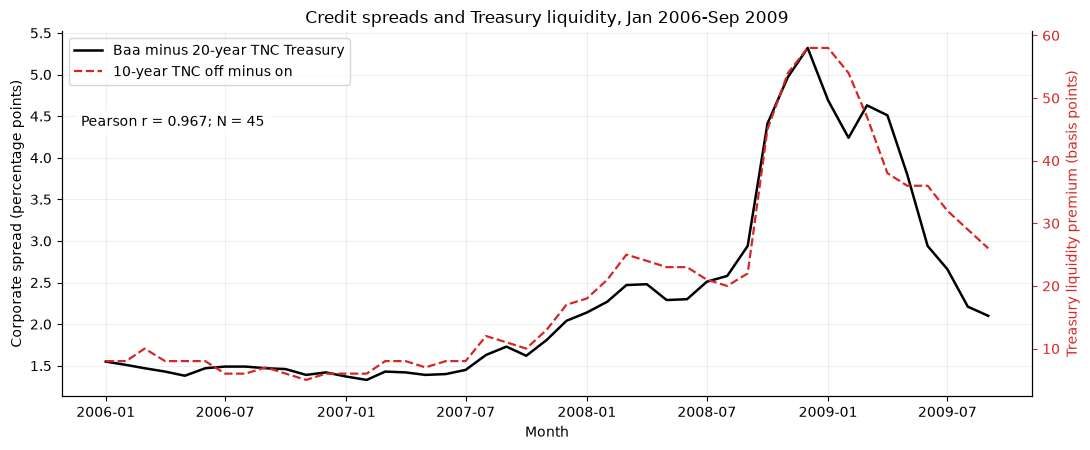

,N,Pearson r,Difference from lecture 0.96
Credit spread,,,
Baa - 20-year TNC (main),45,0.9670,0.0070
Baa - GS10 (maturity mismatch),45,0.9761,0.0161
Baa - 30-year TNC,45,0.9623,0.0023


In [8]:
def plot_spreads(frame, title):
    dates = frame.index.to_timestamp()
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax2 = ax.twinx()
    credit_line, = ax.plot(dates, frame.credit_pp, color='black', lw=1.8,
                           label='Baa minus 20-year TNC Treasury')
    liquidity_line, = ax2.plot(dates, frame.liquidity_bp, color='tab:red', ls='--', lw=1.6,
                               label='10-year TNC off minus on')
    ax.set(xlabel='Month', ylabel='Corporate spread (percentage points)', title=title)
    ax2.set_ylabel('Treasury liquidity premium (basis points)', color='tab:red')
    ax2.tick_params(axis='y', colors='tab:red')
    ax2.grid(False)
    ax.legend(handles=[credit_line, liquidity_line], loc='upper left', frameon=True)
    r = frame.credit_pp.corr(frame.liquidity_bp)
    ax.text(0.02, 0.77, f'Pearson r = {r:.3f}; N = {len(frame)}',
            transform=ax.transAxes, ha='left', va='top',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})
    fig.tight_layout()
    plt.show()

plot_spreads(original, 'Credit spreads and Treasury liquidity, Jan 2006-Sep 2009')

original_rows = []
for column, label in [('credit_pp', 'Baa - 20-year TNC (main)'),
                       ('credit10_pp', 'Baa - GS10 (maturity mismatch)'),
                       ('credit30_pp', 'Baa - 30-year TNC')]:
    d = original[[column, 'liquidity_bp']].dropna()
    r = d[column].corr(d.liquidity_bp)
    original_rows.append({'Credit spread': label, 'N': len(d), 'Pearson r': r,
                           'Difference from lecture 0.96': r - 0.96})
original_comparison = pd.DataFrame(original_rows).set_index('Credit spread')
display(original_comparison.round(4))

In [9]:
original_corr = original.credit_pp.corr(original.liquidity_bp)
display(Markdown(f'''**Comparison with slide 59.** Our main estimate is **{original_corr:.3f}**
from **{len(original)} months**, versus the lecture's reported **0.96**. Both series rise sharply
during the crisis and subsequently decline. The resemblance supports the lecture's crisis-period
co-movement result, but is not an exact numerical replication. The lecture's corporate spread
peaks near 8 pp, whereas the supplied main spread peaks at **{original.credit_pp.max():.2f} pp**
and the GS10 version at **{original.credit10_pp.max():.2f} pp**. Benchmark maturity alone therefore
does not establish why the original corporate series differs. Its underlying index is not
identified by our raw files. Corporate index construction and
Treasury maturity differ, the liquidity series uses fitted TNC yields rounded to one bp, the source
vintage may differ, and our primary endpoint is September rather than October 2009. No observations
were rescaled, winsorized or selected to force the correlation to 0.96. Correlation is invariant to
the pp-to-bp scaling, but reverses sign if the liquidity subtraction is reversed.'''))

**Comparison with slide 59.** Our main estimate is **0.967**
from **45 months**, versus the lecture's reported **0.96**. Both series rise sharply
during the crisis and subsequently decline. The resemblance supports the lecture's crisis-period
co-movement result, but is not an exact numerical replication. The lecture's corporate spread
peaks near 8 pp, whereas the supplied main spread peaks at **5.32 pp**
and the GS10 version at **6.01 pp**. Benchmark maturity alone therefore
does not establish why the original corporate series differs. Its underlying index is not
identified by our raw files. Corporate index construction and
Treasury maturity differ, the liquidity series uses fitted TNC yields rounded to one bp, the source
vintage may differ, and our primary endpoint is September rather than October 2009. No observations
were rescaled, winsorized or selected to force the correlation to 0.96. Correlation is invariant to
the pp-to-bp scaling, but reverses sign if the liquidity subtraction is reversed.

## 6. Does the relationship recur across the three episodes?

### 6.1 Longest-sample context

The full history provides context for the episode comparison. It requires BAA and the selected Treasury curve yields, but not VIX. The regression sample additionally requires monthly VIX. A pooled correlation can hide very different relationships across episodes.

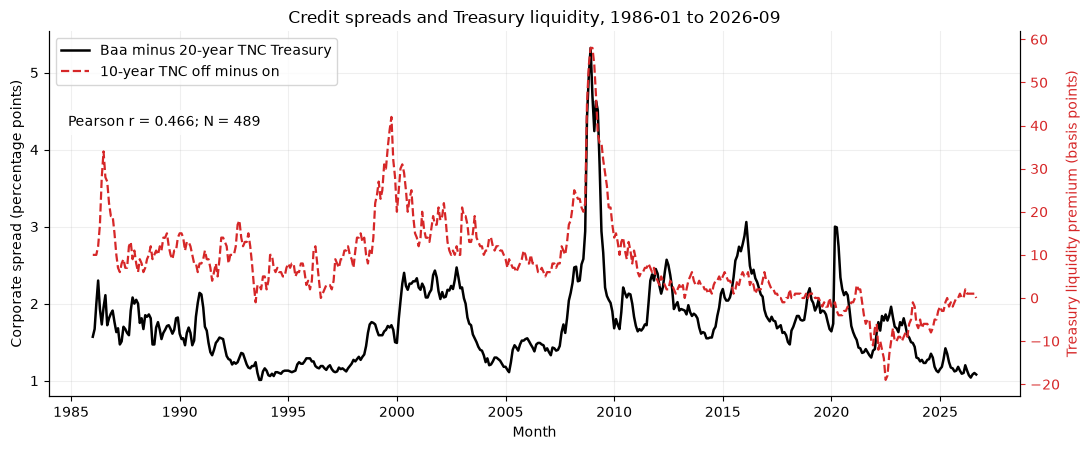

,Start,End,N,Credit/liquidity correlation
Sample,,,,
Original period,2006-01,2009-09,45,0.9670
Extended pair sample,1986-01,2026-09,489,0.4663
Common regression sample,1990-01,2026-09,441,0.4743


The longest pair sample runs from **1986-01 to
2026-09**, with **489 matched months** and a correlation of
**0.466**, compared with **0.967** in the original window.
The near-perfect lecture relationship is weaker in the full history. The central test below
compares 2008-09 with COVID and the rate shock directly; a pooled correlation cannot answer
whether the relationship repeats in either later episode.

In [10]:
plot_spreads(extended, f'Credit spreads and Treasury liquidity, {extended.index.min()} to {extended.index.max()}')

period_rows = []
for name, frame in [('Original period', original), ('Extended pair sample', extended),
                     ('Common regression sample', common)]:
    period_rows.append({'Sample': name, 'Start': str(frame.index.min()), 'End': str(frame.index.max()),
                        'N': len(frame), 'Credit/liquidity correlation': frame.credit_pp.corr(frame.liquidity_bp)})
period_comparison = pd.DataFrame(period_rows).set_index('Sample')
display(period_comparison.round(4))
extended_corr = extended.credit_pp.corr(extended.liquidity_bp)
display(Markdown(f'''The longest pair sample runs from **{extended.index.min()} to
{extended.index.max()}**, with **{len(extended)} matched months** and a correlation of
**{extended_corr:.3f}**, compared with **{original_corr:.3f}** in the original window.
The near-perfect lecture relationship is weaker in the full history. The central test below
compares 2008-09 with COVID and the rate shock directly; a pooled correlation cannot answer
whether the relationship repeats in either later episode.'''))

### 6.2 Equal-length episode samples

All three main windows contain 24 matched monthly observations, including VIX. Levels compare conditions over each episode. Changes measure co-movement from one month to the next. Changes are formed on the full calendar first, then both endpoints must lie within the window, giving **23 changes per 24-month window**. We also show the proxy's observed variation and sign because a nearly flat or negative fitted gap requires careful interpretation.

In [11]:
# Calendar differences are formed before any event filtering.
panel_changes = panel.diff()
episode_frames = {}
episode_rows = []
for name, (start, end) in EPISODES.items():
    window = panel.loc[start:end]
    d = window.dropna(subset=reg_columns).copy()
    expected_months = pd.period_range(start, end, freq='M')
    assert d.index.equals(expected_months), f'Incomplete episode sample: {name}'
    episode_frames[name] = d
    log_step(name, 'Incomplete episode months excluded', len(window) - len(d), len(d))
    dc = panel_changes.loc[expected_months[1:], pair_columns].dropna()
    episode_rows.append({'Episode': name, 'Start': start, 'End': end, 'N levels': len(d),
                         'Credit/liquidity r': d.credit_pp.corr(d.liquidity_bp),
                         'N changes': len(dc), 'Change correlation': dc.credit_pp.corr(dc.liquidity_bp),
                         'Credit/VIX r': d.credit_pp.corr(d.vix),
                         'Liquidity SD (bp)': d.liquidity_bp.std(),
                         'Liquidity minimum (bp)': d.liquidity_bp.min(),
                         'Liquidity maximum (bp)': d.liquidity_bp.max(),
                         'Negative liquidity months': int((d.liquidity_bp < -1e-9).sum())})
episode_comparison = pd.DataFrame(episode_rows).set_index('Episode')
print('Episode correlations, using identical variable definitions')
display(episode_comparison.iloc[:, :8].round(4))
print('Proxy diagnostics, with negative values preserved')
display(episode_comparison.iloc[:, 8:].round(3))
display(pd.DataFrame(cleaning_log).tail(3))

Episode correlations, using identical variable definitions


,Start,End,N levels,Credit/liquidity r,N changes,Change correlation,Credit/VIX r,Liquidity SD (bp)
Episode,,,,,,,,
GFC 2008-09,2008-01,2009-12,24,0.9331,23,0.6916,0.9070,13.5950
COVID 2020-21,2020-01,2021-12,24,0.0845,23,0.0979,0.8769,3.2834
Rate shock 2022-23,2022-01,2023-12,24,-0.6805,23,-0.0555,0.6690,4.2144


Proxy diagnostics, with negative values preserved


,Liquidity minimum (bp),Liquidity maximum (bp),Negative liquidity months
Episode,,,
GFC 2008-09,17.0,58.0,0
COVID 2020-21,-11.0,3.0,20
Rate shock 2022-23,-19.0,-1.0,24


,dataset,step,affected,remaining_rows,note
56,GFC 2008-09,Incomplete episode months excluded,0,24,
57,COVID 2020-21,Incomplete episode months excluded,0,24,
58,Rate shock 2022-23,Incomplete episode months excluded,0,24,


### 6.3 Three episode charts on common scales

The panels use the same left-axis scale for credit spreads and the same right-axis scale for liquidity. This preserves differences in magnitude across episodes. The dotted lines mark September 2008, March 2020 and March 2022 as reference months, without identifying a causal event effect. Negative liquidity values remain visible. Independent left/right units still mean that visual overlap is not itself evidence of correlation.

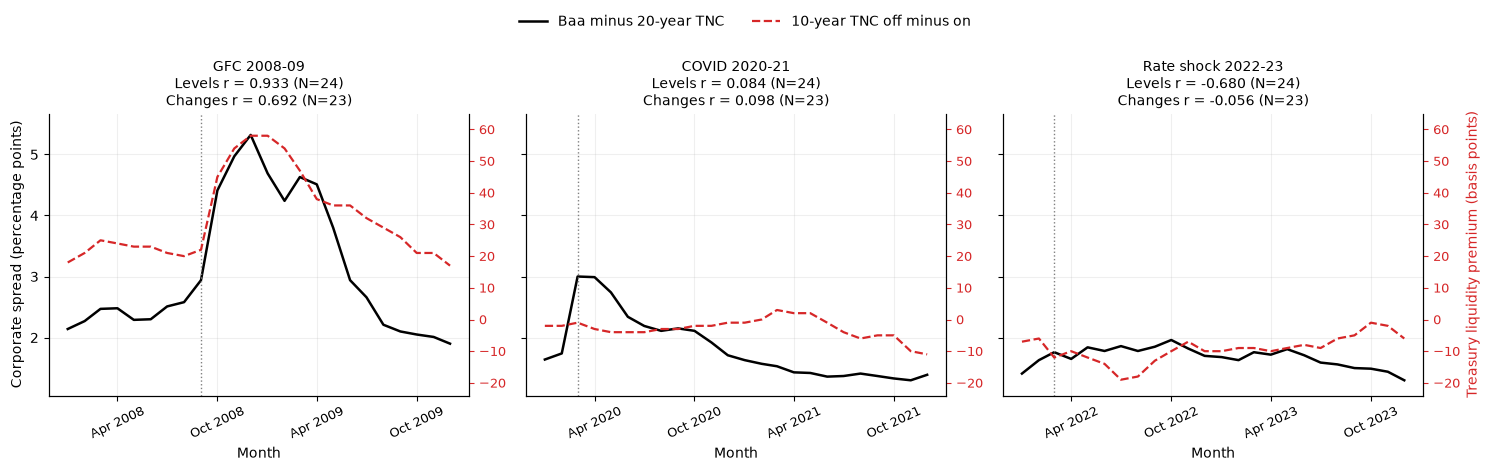

In [12]:
from matplotlib.dates import DateFormatter, MonthLocator

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
all_episodes = pd.concat(episode_frames.values())
credit_limits = (all_episodes.credit_pp.min() - 0.25, all_episodes.credit_pp.max() + 0.35)
liquidity_limits = (all_episodes.liquidity_bp.min() - 5, all_episodes.liquidity_bp.max() + 7)
for ax, (name, d) in zip(axes, episode_frames.items()):
    ax2 = ax.twinx()
    credit_line, = ax.plot(d.index.to_timestamp(), d.credit_pp, color='black', lw=1.8,
                           label='Baa minus 20-year TNC')
    liquidity_line, = ax2.plot(d.index.to_timestamp(), d.liquidity_bp, color='tab:red',
                               ls='--', lw=1.6, label='10-year TNC off minus on')
    ax.set(xlabel='Month', ylim=credit_limits)
    ax2.set_ylim(liquidity_limits)
    ax2.grid(False)
    ax2.tick_params(axis='y', colors='tab:red', labelsize=9)
    ax.xaxis.set_major_locator(MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
    ax.tick_params(axis='x', rotation=25, labelsize=9)
    ax.axvline(pd.Period(ANCHORS[name], 'M').to_timestamp(), color='gray', ls=':', lw=1)
    row = episode_comparison.loc[name]
    ax.set_title(f"{name}\nLevels r = {row['Credit/liquidity r']:.3f} (N=24)\n"
                 f"Changes r = {row['Change correlation']:.3f} (N=23)", fontsize=10)
axes[0].set_ylabel('Corporate spread (percentage points)')
ax2.set_ylabel('Treasury liquidity premium (basis points)', color='tab:red')
fig.legend(handles=[credit_line, liquidity_line], loc='upper center', ncol=2,
           bbox_to_anchor=(0.5, 1.03), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

### 6.4 Anchor-month changes and yield components

The table distinguishes the observed change in a month from a correlation estimated across months. The September 2008, March 2020 and March 2022 rows show source yield levels and changes from the preceding month. In particular,

$$\Delta CS_t = \Delta BAA_t - \Delta y^{TNC,off}_{20,t}.$$

An increase in both corporate and Treasury yields can leave the credit spread almost unchanged. A monthly average can also conceal acute intramonth deterioration and subsequent reversal. The final table compares December-to-December changes over each full window, using the December immediately before its start as the baseline.

In [13]:
anchor_rows = []
window_yield_rows = []
for name, anchor in ANCHORS.items():
    month = pd.Period(anchor, 'M')
    level, change = panel.loc[month], panel_changes.loc[month]
    anchor_rows.append({'Episode': name, 'Anchor month': anchor,
                        'BAA yield (%)': level.BAA, '20-year Treasury yield (%)': level['off_20 Years'],
                        'Credit spread (pp)': level.credit_pp, 'Liquidity (bp)': level.liquidity_bp,
                        'VIX (points)': level.vix,
                        'Off-run 10-year yield (%)': level['off_10 Years'],
                        'On-run 10-year yield (%)': level['on_10 Years'],
                        'Change in BAA (pp)': change.BAA,
                        'Change in Treasury (pp)': change['off_20 Years'],
                        'Change in credit (pp)': change.credit_pp,
                        'Change in liquidity (bp)': change.liquidity_bp,
                        'Change in VIX (points)': change.vix})
    start, end = EPISODES[name]
    baseline = pd.Period(start, 'M') - 1
    delta = panel.loc[pd.Period(end, 'M')] - panel.loc[baseline]
    window_yield_rows.append({'Episode': name, 'Baseline month': str(baseline), 'End month': end,
                              'BAA yield change (pp)': delta.BAA,
                              'Treasury yield change (pp)': delta['off_20 Years'],
                              'Credit spread change (pp)': delta.credit_pp})
anchor_changes = pd.DataFrame(anchor_rows).set_index('Episode')
print('Anchor-month levels')
display(anchor_changes.iloc[:, :8].round(3))
print('Change from the previous month')
display(anchor_changes.iloc[:, 8:].round(3))
print('Yield and spread changes over each complete episode')
episode_yield_changes = pd.DataFrame(window_yield_rows).set_index('Episode')
display(episode_yield_changes.round(3))

gfc_r, covid_r, rate_r = episode_comparison['Credit/liquidity r']
march2020 = anchor_changes.loc['COVID 2020-21']
display(Markdown(f'''**Initial answer:** On equal 24-month windows, the liquidity-credit
correlation is **{gfc_r:.3f}** in 2008-09, **{covid_r:.3f}** in 2020-21, and
**{rate_r:.3f}** in 2022-23. The near-perfect positive association does not recur in either
later main window with this proxy. In March 2020, the main spread increases by
**{march2020['Change in credit (pp)']:.2f} pp**, while the fitted Treasury liquidity gap
changes by **{march2020['Change in liquidity (bp)']:.1f} bp** to
**{march2020['Liquidity (bp)']:.1f} bp**. These are single-month movements, not a March correlation.
The window and proxy sensitivities in Section 9 determine how broadly this answer applies.'''))

Anchor-month levels


,Anchor month,BAA yield (%),20-year Treasury yield (%),Credit spread (pp),Liquidity (bp),VIX (points),Off-run 10-year yield (%),On-run 10-year yield (%)
Episode,,,,,,,,
GFC 2008-09,2008-09,7.31,4.37,2.94,22.0,30.239,3.91,3.69
COVID 2020-21,2020-03,4.29,1.29,3.00,-1.0,57.737,0.86,0.87
Rate shock 2022-23,2022-03,4.29,2.53,1.76,-12.0,26.969,2.00,2.12


Change from the previous month


,Change in BAA (pp),Change in Treasury (pp),Change in credit (pp),Change in liquidity (bp),Change in VIX (points)
Episode,,,,,
GFC 2008-09,0.16,-0.20,0.36,2.0,9.543
COVID 2020-21,0.68,-0.58,1.26,1.0,38.108
Rate shock 2022-23,0.32,0.19,0.13,-6.0,1.220


Yield and spread changes over each complete episode


,Baseline month,End month,BAA yield change (pp),Treasury yield change (pp),Credit spread change (pp)
Episode,,,,,
GFC 2008-09,2007-12,2009-12,-0.28,-0.14,-0.14
COVID 2020-21,2019-12,2021-12,-0.58,-0.30,-0.28
Rate shock 2022-23,2021-12,2023-12,2.34,2.43,-0.09


**Initial answer:** On equal 24-month windows, the liquidity-credit
correlation is **0.933** in 2008-09, **0.084** in 2020-21, and
**-0.680** in 2022-23. The near-perfect positive association does not recur in either
later main window with this proxy. In March 2020, the main spread increases by
**1.26 pp**, while the fitted Treasury liquidity gap
changes by **1.0 bp** to
**-1.0 bp**. These are single-month movements, not a March correlation.
The window and proxy sensitivities in Section 9 determine how broadly this answer applies.

### 6.5 Why a weak COVID proxy result does not imply no liquidity crisis

The Federal Reserve's [June 2020 Monetary Policy Report](https://www.federalreserve.gov/monetarypolicy/2020-06-mpr-part2.htm) documents severe Treasury market dislocations and widening bid-ask spreads in March 2020, particularly for seasoned securities. Our fitted monthly on/off gap measures a relative yield difference, rather than bid-ask spreads, market depth or trading capacity. Both securities can become harder to trade without a large relative-yield change, and monthly averaging can obscure intramonth stress and responses to policy.

These are possible explanations for the discrepancy, not mechanisms identified by our regressions. The negative fitted gaps and small acute-COVID range are explicit measurement limitations. We preserve their sign, show the source yields, and do not substitute an unrelated series. The defensible conclusion concerns whether the **observed proxy relationship** repeats, not whether liquidity mattered in 2020. VIX is equity volatility, so it also omits direct interest-rate volatility relevant to 2022-23.

## 7. Liquidity versus default-related risk across episodes

### 7.1 Full-sample benchmark

The Merton intuition motivates a positive VIX coefficient: higher market volatility may accompany greater asset volatility and expected default risk, making risky debt less valuable. VIX also includes risk aversion and a volatility risk premium, and does not observe firm leverage or recoveries. It cannot cleanly isolate expected default losses.

All three models include an intercept and use the **same complete monthly sample**:

$$\begin{aligned}
A:\quad CS_t &= \alpha_A + \beta_{L,A}L_t + \epsilon_{A,t},\\
B:\quad CS_t &= \alpha_B + \beta_{V,B}VIX_t + \epsilon_{B,t},\\
C:\quad CS_t &= \alpha_C + \beta_{L,C}L_t + \beta_{V,C}VIX_t + \epsilon_{C,t}.
\end{aligned}$$

The dependent variable is in pp, liquidity in bp, and VIX in index points. A liquidity coefficient of 0.01 would mean 0.01 pp (one bp) more corporate spread for a one-bp larger Treasury gap, holding VIX fixed in Model C.

We report conventional OLS t-statistics and **Newey-West HAC t-statistics with 12 monthly lags**. Spreads in levels are persistent, so conventional independent-error inference can exaggerate precision. HAC changes standard errors, not OLS coefficients or R². It does not solve omitted variables, structural change or nonstationarity.

The next subsection repeats A-C separately in the three equal-length episode samples. The full-sample fit is a benchmark rather than the answer to the cross-episode question.

In [14]:
model_columns = {'A: Liquidity': ['liquidity_bp'], 'B: VIX': ['vix'],
                  'C: Liquidity + VIX': ['liquidity_bp', 'vix']}
models = {}
robust_models = {}
regression_rows = []
for name, columns in model_columns.items():
    fit = sm.OLS(common.credit_pp, sm.add_constant(common[columns])).fit()
    hac = fit.get_robustcov_results(cov_type='HAC', maxlags=12, use_correction=True, use_t=True)
    models[name], robust_models[name] = fit, hac
    row = {'Model': name, 'N': int(fit.nobs), 'R squared': fit.rsquared}
    for term, label in [('const', 'Intercept'), ('liquidity_bp', 'Liquidity'), ('vix', 'VIX')]:
        if term in fit.params.index:
            j = fit.params.index.get_loc(term)
            row[f'{label}: coefficient'] = fit.params[term]
            row[f'{label}: OLS t'] = fit.tvalues[term]
            row[f'{label}: HAC t'] = hac.tvalues[j]
    regression_rows.append(row)

# Transpose keeps the three models readable side by side.
regression_table = pd.DataFrame(regression_rows).set_index('Model')
order = ['Intercept: coefficient', 'Intercept: OLS t', 'Intercept: HAC t',
         'Liquidity: coefficient', 'Liquidity: OLS t', 'Liquidity: HAC t',
         'VIX: coefficient', 'VIX: OLS t', 'VIX: HAC t', 'R squared', 'N']
display(regression_table[order].T.round(4).fillna('—'))
print(f'Identical sample for A-C: {common.index.min()} to {common.index.max()}, N = {len(common)}')
print('Missing regressor entry means the variable is absent from that model.')

Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,1.5345,0.7241,0.7903
Intercept: OLS t,50.4414,11.9795,13.2466
Intercept: HAC t,15.1086,3.0685,4.4174
Liquidity: coefficient,0.0262,—,0.0122
Liquidity: OLS t,11.2876,—,5.5810
Liquidity: HAC t,2.1022,—,1.8001
VIX: coefficient,—,0.052,0.0438
VIX: OLS t,—,17.8689,13.7871
VIX: HAC t,—,4.0377,5.7172
R squared,0.2249,0.4211,0.4595


Identical sample for A-C: 1990-01 to 2026-09, N = 441
Missing regressor entry means the variable is absent from that model.


In [15]:
vix_corr = common.credit_pp.corr(common.vix)
liq_vix_corr = common.liquidity_bp.corr(common.vix)
vix_rows = []
for name, start, end in [('All common months', str(common.index.min()), str(common.index.max())),
                         ('Available part of lecture era', '1990-01', '2013-12'),
                         ('Original crisis figure window', ORIGINAL_START, ORIGINAL_END)]:
    for column, label in [('credit_pp', 'Baa - 20-year TNC'), ('credit10_pp', 'Baa - GS10')]:
        d = panel.loc[start:end, [column, 'vix']].dropna()
        vix_rows.append({'Window': name, 'Credit definition': label, 'Start': str(d.index.min()),
                         'End': str(d.index.max()), 'N': len(d),
                         'Credit/VIX r': d[column].corr(d.vix)})
vix_comparison = pd.DataFrame(vix_rows)
display(vix_comparison.round(4))

r2a, r2b, r2c = [models[name].rsquared for name in model_columns]
fit_c = models['C: Liquidity + VIX']
hac_c = robust_models['C: Liquidity + VIX']
incremental = pd.Series({'R² added by liquidity after VIX': r2c - r2b,
                         'R² added by VIX after liquidity': r2c - r2a,
                         'Liquidity/VIX correlation': liq_vix_corr}, name='Value')
display(incremental.to_frame().round(4))

display(Markdown(f'''**Findings.** Liquidity alone has R² **{r2a:.3f}**, VIX alone
**{r2b:.3f}**, and both together **{r2c:.3f}**. VIX has the larger univariate fit.
Adding liquidity after VIX raises R² by **{r2c-r2b:.3f}**. In Model C the liquidity
coefficient is **{fit_c.params['liquidity_bp']:.4f} pp per bp**, and VIX's coefficient is
**{fit_c.params['vix']:.4f} pp per index point**. Liquidity's HAC t-statistic is
**{hac_c.tvalues[1]:.2f}**, versus its conventional t-statistic of **{fit_c.tvalues['liquidity_bp']:.2f}**,
so its conditional statistical evidence is sensitive to persistence-robust inference.

The main spread's VIX correlation is **{vix_corr:.3f}** on the {len(common)} common months,
compared with the lecture's **0.64**. Slide 51 describes 1986-2013, while the supplied VIX starts
in 1990. The table therefore also reports the observable 1990-2013 part and the GS10 definition.
Closeness of an extended-sample estimate to 0.64 does not demonstrate exact replication.

**Interpretation.** The two regressors share market-wide shocks (their correlation is
{liq_vix_corr:.3f}), so their univariate R² values overlap. The combined fit measures in-sample
variation associated with these proxies, not an allocation of the spread into liquidity and default
components. Funding pressure, risk aversion and recession news can move both regressors and credit
spreads simultaneously. Reverse causation and missing firm fundamentals remain possible.'''))

,Window,Credit definition,Start,End,N,Credit/VIX r
0,All common months,Baa - 20-year TNC,1990-01,2026-09,441,0.6489
1,All common months,Baa - GS10,1990-01,2026-09,441,0.6310
2,Available part of lecture era,Baa - 20-year TNC,1990-01,2013-12,288,0.7635
3,Available part of lecture era,Baa - GS10,1990-01,2013-12,288,0.7075
4,Original crisis figure window,Baa - 20-year TNC,2006-01,2009-09,45,0.9395
5,Original crisis figure window,Baa - GS10,2006-01,2009-09,45,0.9257


,Value
R² added by liquidity after VIX,0.0384
R² added by VIX after liquidity,0.2346
Liquidity/VIX correlation,0.4631


**Findings.** Liquidity alone has R² **0.225**, VIX alone
**0.421**, and both together **0.460**. VIX has the larger univariate fit.
Adding liquidity after VIX raises R² by **0.038**. In Model C the liquidity
coefficient is **0.0122 pp per bp**, and VIX's coefficient is
**0.0438 pp per index point**. Liquidity's HAC t-statistic is
**1.80**, versus its conventional t-statistic of **5.58**,
so its conditional statistical evidence is sensitive to persistence-robust inference.

The main spread's VIX correlation is **0.649** on the 441 common months,
compared with the lecture's **0.64**. Slide 51 describes 1986-2013, while the supplied VIX starts
in 1990. The table therefore also reports the observable 1990-2013 part and the GS10 definition.
Closeness of an extended-sample estimate to 0.64 does not demonstrate exact replication.

**Interpretation.** The two regressors share market-wide shocks (their correlation is
0.463), so their univariate R² values overlap. The combined fit measures in-sample
variation associated with these proxies, not an allocation of the spread into liquidity and default
components. Funding pressure, risk aversion and recession news can move both regressors and credit
spreads simultaneously. Reverse causation and missing firm fundamentals remain possible.

### 7.2 Identical A-C specifications within each episode

For each 24-month window, run the same three models with an intercept. All A-C specifications within an episode use exactly the same months. Coefficients retain their original units. We report **conventional OLS t-statistics** and **HAC t-statistics with three monthly lags and a finite-sample correction**. Three lags provide a shorter-horizon adjustment than the full sample's 12-lag benchmark for these small windows. A later table varies the lag choice.

We compare R² across A, B and C, including how much liquidity adds after VIX. Changes in conditional coefficients are descriptive, not a formal structural-break or equality-of-correlations test. With only 24 observations and persistent levels, the t-statistics are fragile. We do not estimate multivariable regressions from a single month or the six-observation acute windows.

In [16]:
episode_models = {}
episode_model_rows = []
episode_fit_rows = []
for episode, d in episode_frames.items():
    for model, columns in model_columns.items():
        fit = sm.OLS(d.credit_pp, sm.add_constant(d[columns])).fit()
        hac = fit.get_robustcov_results(cov_type='HAC', maxlags=3,
                                       use_correction=True, use_t=True)
        episode_models[(episode, model)] = fit
        row = {'Episode': episode, 'Model': model, 'N': int(fit.nobs), 'R squared': fit.rsquared}
        for term, label in [('const', 'Intercept'), ('liquidity_bp', 'Liquidity'), ('vix', 'VIX')]:
            if term in fit.params.index:
                j = fit.params.index.get_loc(term)
                row[f'{label}: coefficient'] = fit.params[term]
                row[f'{label}: OLS t'] = fit.tvalues[term]
                row[f'{label}: HAC t'] = hac.tvalues[j]
        episode_model_rows.append(row)
    a, b, c = [episode_models[(episode, model)] for model in model_columns]
    episode_fit_rows.append({'Episode': episode, 'N': len(d), 'R² A: Liquidity': a.rsquared,
                             'R² B: VIX': b.rsquared, 'R² C: Both': c.rsquared,
                             'R² added by liquidity after VIX': c.rsquared - b.rsquared,
                             'Liquidity/VIX correlation': d.liquidity_bp.corr(d.vix)})
episode_regressions = pd.DataFrame(episode_model_rows).set_index(['Episode', 'Model'])
for episode in EPISODES:
    print(episode)
    display(episode_regressions.loc[episode, order].T.round(4).fillna('—'))
episode_fit = pd.DataFrame(episode_fit_rows).set_index('Episode')
print('Comparison of explanatory fit on identical samples')
display(episode_fit.round(4))

GFC 2008-09


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,0.6372,0.5662,0.4610
Intercept: OLS t,2.9076,2.1011,2.2367
Intercept: HAC t,3.1438,1.5649,1.9631
Liquidity: coefficient,0.0769,—,0.0494
Liquidity: OLS t,12.173,—,4.1466
Liquidity: HAC t,17.659,—,6.9669
VIX: coefficient,—,0.0788,0.0329
VIX: OLS t,—,10.1037,2.6169
VIX: HAC t,—,6.6154,3.3394
R squared,0.8707,0.8227,0.9025


COVID 2020-21


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,1.8606,0.6212,0.6256
Intercept: OLS t,12.8778,4.1426,3.8004
Intercept: HAC t,8.4001,2.8839,2.8537
Liquidity: coefficient,0.0135,—,0.0012
Liquidity: OLS t,0.3976,—,0.0740
Liquidity: HAC t,0.3206,—,0.0569
VIX: coefficient,—,0.0492,0.0492
VIX: OLS t,—,8.5574,8.3232
VIX: HAC t,—,6.1598,6.0301
R squared,0.0071,0.769,0.7690


Rate shock 2022-23


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,1.4332,1.2394,1.2368
Intercept: OLS t,23.4594,11.6387,13.2055
Intercept: HAC t,22.571,7.8991,9.8108
Liquidity: coefficient,-0.0263,—,-0.0174
Liquidity: OLS t,-4.3556,—,-2.7290
Liquidity: HAC t,-5.2727,—,-2.6314
VIX: coefficient,—,0.0206,0.0131
VIX: OLS t,—,4.2222,2.5793
VIX: HAC t,—,3.0881,1.7199
R squared,0.463,0.4476,0.5922


Comparison of explanatory fit on identical samples


,N,R² A: Liquidity,R² B: VIX,R² C: Both,R² added by liquidity after VIX,Liquidity/VIX correlation
Episode,,,,,,
GFC 2008-09,24,0.8707,0.8227,0.9025,0.0798,0.8820
COVID 2020-21,24,0.0071,0.7690,0.7690,0.0001,0.0875
Rate shock 2022-23,24,0.4630,0.4476,0.5922,0.1446,-0.5379


In [17]:
gfc_fit, covid_fit, rate_fit = [episode_fit.loc[name] for name in EPISODES]
display(Markdown(f'''**Regression comparison:** Liquidity alone explains
**{100*gfc_fit['R² A: Liquidity']:.1f}%** of credit-spread variation within 2008-09,
**{100*covid_fit['R² A: Liquidity']:.1f}%** within 2020-21, and
**{100*rate_fit['R² A: Liquidity']:.1f}%** within 2022-23. The rate-window association has the
opposite sign, so its R² cannot be interpreted as a repetition of the positive 2008 relationship.
Liquidity adds **{gfc_fit['R² added by liquidity after VIX']:.3f}** to R² after VIX in the GFC,
versus **{covid_fit['R² added by liquidity after VIX']:.3f}** in COVID and
**{rate_fit['R² added by liquidity after VIX']:.3f}** in the rate shock.

VIX's fit is also episode-dependent. A positive VIX association is consistent with Merton's
volatility intuition, but VIX contains risk aversion and volatility premiums as well as
default-related information. Liquidity and VIX can respond to common shocks and policy actions.
Neither proxy's R² is a share of the average spread or a causal contribution.'''))

**Regression comparison:** Liquidity alone explains
**87.1%** of credit-spread variation within 2008-09,
**0.7%** within 2020-21, and
**46.3%** within 2022-23. The rate-window association has the
opposite sign, so its R² cannot be interpreted as a repetition of the positive 2008 relationship.
Liquidity adds **0.080** to R² after VIX in the GFC,
versus **0.000** in COVID and
**0.145** in the rate shock.

VIX's fit is also episode-dependent. A positive VIX association is consistent with Merton's
volatility intuition, but VIX contains risk aversion and volatility premiums as well as
default-related information. Liquidity and VIX can respond to common shocks and policy actions.
Neither proxy's R² is a share of the average spread or a causal contribution.

## 8. The credit spread puzzle: spread levels versus expected losses

Expected annual credit loss is approximately:

$$EL = p(\text{default})\,(1-\text{recovery rate}).$$

Slide 55 reports a historical **Baa annual credit-loss rate of 0.124%**, based on Moody's default and recovery evidence for **1982-2008**. Its separate average-spread column covers **1987-2011**. We use **0.124 percentage point per year = 12.4 bp per year** as a fixed illustrative expected-loss assumption. We do not infer a default probability or recovery rate separately because neither the supplied files nor this table identify the separate Baa inputs.

The comparison uses the full regression sample, the longer two-spread sample, and each of the three 24-month episodes. The same historical loss assumption is held fixed for comparability; it is not an estimate of actual losses during any episode. Annualized yield spreads can be compared with annual loss rates without dividing the spread by 12. This is a rough yield-versus-loss comparison, not a full cash-flow pricing model.

In [18]:
EXPECTED_LOSS_PP = 0.124  # Lecture slide 55: Baa annual credit loss, 1982-2008.
puzzle_rows = []
for name, frame in [('Common regression sample', common), ('Extended pair sample', extended),
                     *episode_frames.items()]:
    average = frame.credit_pp.mean()
    residual = average - EXPECTED_LOSS_PP
    puzzle_rows.append({'Sample': name, 'Start': str(frame.index.min()), 'End': str(frame.index.max()),
                        'N': len(frame), 'Average spread (pp)': average,
                        'Expected annual loss (pp)': EXPECTED_LOSS_PP,
                        'Residual spread (pp)': residual,
                        'Expected loss / spread (%)': 100 * EXPECTED_LOSS_PP / average,
                        'Residual / spread (%)': 100 * residual / average})
puzzle = pd.DataFrame(puzzle_rows).set_index('Sample')
display(puzzle.round(4))

avg_spread = common.credit_pp.mean()
residual_spread = avg_spread - EXPECTED_LOSS_PP
display(Markdown(f'''For **{common.index.min()} to {common.index.max()}**, the average main
spread is **{avg_spread:.3f} pp ({100*avg_spread:.1f} bp)**. Subtracting the assumed
**0.124 pp (12.4 bp)** expected annual loss leaves **{residual_spread:.3f} pp
({100*residual_spread:.1f} bp)**, or **{100*residual_spread/avg_spread:.1f}%** of the average spread.
This shows that the historical expected-loss baseline is small relative to the observed spread.'''))

,Start,End,N,Average spread (pp),Expected annual loss (pp),Residual spread (pp),Expected loss / spread (%),Residual / spread (%)
Sample,,,,,,,,
Common regression sample,1990-01,2026-09,441,1.7344,0.124,1.6104,7.1493,92.8507
Extended pair sample,1986-01,2026-09,489,1.7374,0.124,1.6134,7.1373,92.8627
GFC 2008-09,2008-01,2009-12,24,3.1008,0.124,2.9768,3.9989,96.0011
COVID 2020-21,2020-01,2021-12,24,1.8229,0.124,1.6989,6.8023,93.1977
Rate shock 2022-23,2022-01,2023-12,24,1.6763,0.124,1.5523,7.3975,92.6025


For **1990-01 to 2026-09**, the average main
spread is **1.734 pp (173.4 bp)**. Subtracting the assumed
**0.124 pp (12.4 bp)** expected annual loss leaves **1.610 pp
(161.0 bp)**, or **92.9%** of the average spread.
This shows that the historical expected-loss baseline is small relative to the observed spread.

**What explains the residual?** It may include a default risk premium because defaults cluster in bad times and recovery rates can fall just when losses rise. Investors may also require compensation for corporate illiquidity, state/local tax differences relative to Treasuries, embedded call/put options, rating migration, and other bond characteristics. Treasury convenience value and remaining maturity/duration mismatch also affect this yield difference.

The 1982-2008 historical loss average need not equal investors' expectations in 1990-2026 or during each crisis. Rating composition, leverage and recoveries can change. The calculation is therefore an illustrative credit spread puzzle using the assigned baseline, not an estimate of each month's true expected loss.

The regressions support studying liquidity alongside volatility, but cannot identify how many basis points of the **average residual** are liquidity compensation. Their R² values concern **variation around a mean**, not the level of that mean. Multiplying R² by the residual spread would be invalid. Even an estimated liquidity coefficient times average liquidity would require an identified counterfactual and a correctly specified pricing model before it could be interpreted as a causal level decomposition.

Across the three episodes, the table asks whether a fixed historical loss baseline leaves a large residual, not whether the residual has the same composition. The weak COVID liquidity fit and the negative rate-window slope particularly caution against labeling the residual entirely as liquidity.

## 9. Sensitivity to windows, changes, benchmarks and inference

### 9.1 Window length and levels versus changes

The table reports the main 24-month samples, calendar 2008 and 2020, calendar 2022 and 2023 separately, and equal six-month windows beginning September 2008, March 2020 and March 2022. These dates are declared in Section 2, not optimized for correlation. The shorter windows distinguish acute shocks from later adjustment, though six observations provide weak evidence and none of these windows contains only one type of shock.

The original lecture period and full-history extension remain as benchmarks. First differences are always computed on the full calendar. Both months must be inside a selected window, so 24-, 12- and 6-month windows have 23, 11 and 5 potential changes. This intentionally excludes the change into the first month. The separate anchor-month table includes that initial shock change, including February-to-March 2020. This boundary choice matters and is shown as an additional sensitivity below.

In [19]:
def window_correlations(label, start, end):
    window = panel.loc[start:end]
    d = window.dropna(subset=reg_columns)
    months = pd.period_range(start, end, freq='M')
    dc = panel_changes.loc[months[1:], pair_columns].dropna()
    return {'Window': label, 'Start': start, 'End': end, 'N levels': len(d),
            'Level r': d.credit_pp.corr(d.liquidity_bp),
            'N changes': len(dc), 'Change r': dc.credit_pp.corr(dc.liquidity_bp),
            'Credit/VIX r': d.credit_pp.corr(d.vix)}

window_rows = []
for name, (start, end) in {**EPISODES, **YEAR_WINDOWS, **ACUTE_WINDOWS}.items():
    window_rows.append(window_correlations(name, start, end))
window_comparison = pd.DataFrame(window_rows).set_index('Window')
display(window_comparison.round(4))

# Include the initial entry change as an explicit alternative, not a hidden boundary choice.
entry_rows = []
for name, (start, end) in ACUTE_WINDOWS.items():
    d = panel_changes.loc[start:end, pair_columns].dropna()
    entry_rows.append({'Acute window': name, 'N changes including entry': len(d),
                       'Change r including entry': d.credit_pp.corr(d.liquidity_bp),
                       'N changes within window': window_comparison.loc[name, 'N changes'],
                       'Change r within window': window_comparison.loc[name, 'Change r']})
entry_sensitivity = pd.DataFrame(entry_rows).set_index('Acute window')
print('Sensitivity to including the initial shock-month change')
display(entry_sensitivity.round(4))

calendar_changes = panel_changes.loc[extended.index[1:], pair_columns].dropna()
change_corr = calendar_changes.credit_pp.corr(calendar_changes.liquidity_bp)
benchmark_rows = []
for label, frame in [('Lecture Jan 2006-Sep 2009', original),
                      ('Lecture endpoint through Oct 2009', panel.loc['2006-01':'2009-10']),
                      ('Full extended sample', extended)]:
    d = frame[pair_columns].dropna()
    benchmark_rows.append({'Window': label, 'Start': str(d.index.min()), 'End': str(d.index.max()),
                           'N': len(d), 'Level r': d.credit_pp.corr(d.liquidity_bp)})
display(pd.DataFrame(benchmark_rows).set_index('Window').round(4))
print(f'Full extended monthly-change r = {change_corr:.4f}; N = {len(calendar_changes)}')

,Start,End,N levels,Level r,N changes,Change r,Credit/VIX r
Window,,,,,,,
GFC 2008-09,2008-01,2009-12,24,0.9331,23,0.6916,0.9070
COVID 2020-21,2020-01,2021-12,24,0.0845,23,0.0979,0.8769
Rate shock 2022-23,2022-01,2023-12,24,-0.6805,23,-0.0555,0.6690
Calendar 2008,2008-01,2008-12,12,0.9810,11,0.9544,0.9383
Calendar 2020,2020-01,2020-12,12,-0.2747,11,0.2877,0.8859
Calendar 2022,2022-01,2022-12,12,-0.4790,11,-0.1756,0.5326
Calendar 2023,2023-01,2023-12,12,-0.7012,11,0.3725,0.5809
GFC Sep 2008-Feb 2009,2008-09,2009-02,6,0.9184,5,0.9541,0.7561
COVID Mar-Aug 2020,2020-03,2020-08,6,0.5529,5,-0.2386,0.8432


Sensitivity to including the initial shock-month change


,N changes including entry,Change r including entry,N changes within window,Change r within window
Acute window,,,,
GFC Sep 2008-Feb 2009,6,0.9255,5,0.9541
COVID Mar-Aug 2020,6,0.4291,5,-0.2386
Rates Mar-Aug 2022,6,-0.7303,5,-0.6640


,Start,End,N,Level r
Window,,,,
Lecture Jan 2006-Sep 2009,2006-01,2009-09,45,0.9670
Lecture endpoint through Oct 2009,2006-01,2009-10,46,0.9661
Full extended sample,1986-01,2026-09,489,0.4663


Full extended monthly-change r = 0.2774; N = 488


### 9.2 Treasury maturity and liquidity tenor

Keep the same 24 months within each episode, then change one definition at a time. Corporate benchmark alternatives use GS10 and the available 30-year TNC yield. Liquidity alternatives use the matched 2- and 5-year off/on pairs. Negative results retain their sign. These checks reveal measurement sensitivity rather than provide a menu from which to choose the strongest relationship.

In [20]:
definition_rows = []
for name, d in episode_frames.items():
    definition_rows.append({'Episode': name, 'N': len(d),
                            'Main: Baa-20y / liquidity10y': d.credit_pp.corr(d.liquidity_bp),
                            'Baa-GS10 / liquidity10y': d.credit10_pp.corr(d.liquidity_bp),
                            'Baa-30y / liquidity10y': d.credit30_pp.corr(d.liquidity_bp),
                            'Baa-20y / liquidity2y': d.credit_pp.corr(d.liquidity2_bp),
                            'Baa-20y / liquidity5y': d.credit_pp.corr(d.liquidity5_bp)})
definition_sensitivity = pd.DataFrame(definition_rows).set_index('Episode')
display(definition_sensitivity.round(4))

print('Full-sample GS10 regression sensitivity on the same 441 months')
gs10_rows = []
for name, columns in model_columns.items():
    fit = sm.OLS(common.credit10_pp, sm.add_constant(common[columns])).fit()
    hac = fit.get_robustcov_results(cov_type='HAC', maxlags=12, use_correction=True, use_t=True)
    row = {'Model': name, 'N': int(fit.nobs), 'R squared': fit.rsquared}
    for j, term in enumerate(fit.params.index):
        row[f'{term}: coefficient'] = fit.params[term]
        row[f'{term}: OLS t'] = fit.tvalues[term]
        row[f'{term}: HAC t'] = hac.tvalues[j]
    gs10_rows.append(row)
display(pd.DataFrame(gs10_rows).set_index('Model').T.round(4).fillna('—'))

,N,Main: Baa-20y / liquidity10y,Baa-GS10 / liquidity10y,Baa-30y / liquidity10y,Baa-20y / liquidity2y,Baa-20y / liquidity5y
Episode,,,,,,
GFC 2008-09,24,0.9331,0.9384,0.9358,-0.5151,-0.0146
COVID 2020-21,24,0.0845,0.1379,-0.0021,-0.2298,0.6038
Rate shock 2022-23,24,-0.6805,-0.7188,-0.6323,0.3289,0.5065


Full-sample GS10 regression sensitivity on the same 441 months


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
N,441.0,441.0,441.0000
R squared,0.2592,0.3981,0.4580
const: coefficient,2.0201,1.0953,1.1949
const: OLS t,56.3877,14.7537,16.6028
const: HAC t,18.1319,4.4526,6.8499
liquidity_bp: coefficient,0.0339,—,0.0184
liquidity_bp: OLS t,12.3925,—,6.9559
liquidity_bp: HAC t,2.5756,—,2.3646
vix: coefficient,—,0.0609,0.0485
vix: OLS t,—,17.04,12.6751


### 9.3 HAC lag sensitivity and comparison limits

The table holds each episode's Model C coefficients fixed and compares HAC t-statistics with 1, 3 and 6 lags. Changing the covariance estimate changes precision, not the fitted slope, correlation or R². Small samples and serial dependence limit inference even when a t-statistic looks large. We do not apply an independent-observation Fisher correlation test to these persistent monthly levels.

In [21]:
hac_rows = []
for episode in EPISODES:
    fit = episode_models[(episode, 'C: Liquidity + VIX')]
    row = {'Episode': episode, 'Liquidity coefficient': fit.params['liquidity_bp'],
            'VIX coefficient': fit.params['vix']}
    for lag in [1, 3, 6]:
        hac = fit.get_robustcov_results(cov_type='HAC', maxlags=lag,
                                       use_correction=True, use_t=True)
        row[f'Liquidity HAC t, lag {lag}'] = hac.tvalues[1]
        row[f'VIX HAC t, lag {lag}'] = hac.tvalues[2]
    hac_rows.append(row)
hac_sensitivity = pd.DataFrame(hac_rows).set_index('Episode')
display(hac_sensitivity.round(4))

covid_acute = window_comparison.loc['COVID Mar-Aug 2020']
covid_year = window_comparison.loc['Calendar 2020']
rate_change_r = episode_comparison.loc['Rate shock 2022-23', 'Change correlation']
covid_entry = entry_sensitivity.loc['COVID Mar-Aug 2020']
covid_liq5 = definition_sensitivity.loc['COVID 2020-21', 'Baa-20y / liquidity5y']
rate_liq5 = definition_sensitivity.loc['Rate shock 2022-23', 'Baa-20y / liquidity5y']
display(Markdown(f'''**What survives the sensitivity checks?** The GFC is strongly positive
in both the lecture window and calendar 2008. COVID is window-sensitive: its levels correlation
is **{covid_year['Level r']:.3f}** in calendar 2020 and **{covid_acute['Level r']:.3f}** in
March-August 2020, compared with **{covid_r:.3f}** in 2020-21. Thus it would be too strong
to claim that COVID never shows positive co-movement, but there is no stable near-perfect repeat.
The acute COVID change correlation also depends on the entry boundary:
**{covid_entry['Change r within window']:.3f}** for the five within-window changes versus
**{covid_entry['Change r including entry']:.3f}** for six changes including February-to-March.

The 2022-23 main levels relationship is negative (**{rate_r:.3f}**), while its monthly-change
correlation is **{rate_change_r:.3f}**. This suggests that its levels association should not be
read as a stable month-to-month liquidity mechanism. Benchmark/tenor sensitivity and negative
fitted premiums further limit claims about the underlying economic importance of liquidity.
For example, the 5-year liquidity alternative gives positive correlations of **{covid_liq5:.3f}**
in COVID and **{rate_liq5:.3f}** in the rate shock. The sign of the rate-window result therefore
depends on tenor. The conclusion is specifically about recurrence of the near-perfect **10-year**
proxy relationship, rather than a claim that all measures of liquidity give the same answer.'''))

,Liquidity coefficient,VIX coefficient,"Liquidity HAC t, lag 1","VIX HAC t, lag 1","Liquidity HAC t, lag 3","VIX HAC t, lag 3","Liquidity HAC t, lag 6","VIX HAC t, lag 6"
Episode,,,,,,,,
GFC 2008-09,0.0494,0.0329,5.3860,3.2161,6.9669,3.3394,10.2997,3.6164
COVID 2020-21,0.0012,0.0492,0.0680,5.6140,0.0569,6.0301,0.0537,6.7444
Rate shock 2022-23,-0.0174,0.0131,-3.0736,1.9354,-2.6314,1.7199,-2.4551,1.7140


**What survives the sensitivity checks?** The GFC is strongly positive
in both the lecture window and calendar 2008. COVID is window-sensitive: its levels correlation
is **-0.275** in calendar 2020 and **0.553** in
March-August 2020, compared with **0.084** in 2020-21. Thus it would be too strong
to claim that COVID never shows positive co-movement, but there is no stable near-perfect repeat.
The acute COVID change correlation also depends on the entry boundary:
**-0.239** for the five within-window changes versus
**0.429** for six changes including February-to-March.

The 2022-23 main levels relationship is negative (**-0.680**), while its monthly-change
correlation is **-0.056**. This suggests that its levels association should not be
read as a stable month-to-month liquidity mechanism. Benchmark/tenor sensitivity and negative
fitted premiums further limit claims about the underlying economic importance of liquidity.
For example, the 5-year liquidity alternative gives positive correlations of **0.604**
in COVID and **0.506** in the rate shock. The sign of the rate-window result therefore
depends on tenor. The conclusion is specifically about recurrence of the near-perfect **10-year**
proxy relationship, rather than a claim that all measures of liquidity give the same answer.

## 10. Answer to the research question and policy implications

The question concerns recurrence across three named episodes. The answer below uses the common definitions and windows above, with sensitivity results qualifying its scope.

In [22]:
rate_yield_changes = episode_yield_changes.loc['Rate shock 2022-23']
display(Markdown(f'''
**Answer:** With the supplied monthly **10-year** TNC liquidity proxy, 2008's near-perfect positive link
**does not repeat consistently** in March 2020 COVID or the 2022-23 rate shock. This distinguishes
the three named episodes; it does not prove that 2008 is unique across all historical crises.

| Equal 24-month episode | Levels correlation | Monthly-change correlation | N levels / changes |
|---|---:|---:|---:|
| 2008-09 | {gfc_r:.3f} | {episode_comparison.loc['GFC 2008-09', 'Change correlation']:.3f} | 24 / 23 |
| 2020-21 | {covid_r:.3f} | {episode_comparison.loc['COVID 2020-21', 'Change correlation']:.3f} | 24 / 23 |
| 2022-23 | {rate_r:.3f} | {rate_change_r:.3f} | 24 / 23 |

**2008 benchmark:** The original January 2006-September 2009 estimate is **{original_corr:.3f}**
(N={len(original)}), close to the lecture's reported 0.96. On the main 2008-09 comparison window,
liquidity has strong explanatory fit and adds information beyond VIX.

**COVID:** In March 2020, the main credit spread increases **{march2020['Change in credit (pp)']:.2f} pp**,
but the fitted monthly liquidity proxy moves only **{march2020['Change in liquidity (bp)']:.1f} bp**.
The COVID relationship changes with the window and boundary convention. Its main liquidity-only
R² is **{covid_fit['R² A: Liquidity']:.3f}**, and adding liquidity after VIX adds only
**{covid_fit['R² added by liquidity after VIX']:.4f}** to R². This is a failure to reproduce the
2008 pattern with this proxy, not evidence that COVID had no liquidity disruption.

**2022-23:** The negative levels association has liquidity-only R²
**{rate_fit['R² A: Liquidity']:.3f}**, but the near-zero change correlation weakens a persistent
co-movement interpretation. From December 2021 to December 2023, BAA rises
**{rate_yield_changes['BAA yield change (pp)']:.2f} pp**, while the 20-year Treasury yield rises
**{rate_yield_changes['Treasury yield change (pp)']:.2f} pp**. The spread therefore changes by
**{rate_yield_changes['Credit spread change (pp)']:.2f} pp**. Higher borrowing yields alone
do not identify wider credit spreads. Banking stress and omitted interest-rate volatility
complicate a window labeled a rate shock. The 5-year proxy even gives a positive levels
correlation of **{rate_liq5:.3f}**, emphasizing the tenor-specific nature of the finding.

**Credit spread puzzle:** The full regression sample's average spread is **{avg_spread:.3f} pp**.
The historical **0.124 pp** annual-loss assumption leaves **{residual_spread:.3f} pp**.
Episode-specific averages also leave substantial residual spreads, but neither R² nor the
liquidity slope identifies their liquidity share.

**For central banks:** A relationship calibrated during 2008 should not be treated as a universal
conversion from Treasury liquidity to corporate borrowing costs. Monitor corporate spreads,
equity and rate volatility, and direct trading measures such as depth and bid-ask spreads together.
The present data support that monitoring implication, but cannot estimate a liquidity facility's
causal effect or the optimal response in any episode.

**Limitations:** Twenty-four observations per episode and only six per acute window are small
samples. Monthly averages miss daily March dynamics and policy timing. The fitted, rounded
Treasury gap is a relative-yield proxy with negative values in later episodes. Corporate duration
matching is approximate, VIX does not isolate default risk, and common shocks prevent causal
attribution. Sensitivity to windows and differencing boundaries is reported rather than hidden.
'''))


**Answer:** With the supplied monthly **10-year** TNC liquidity proxy, 2008's near-perfect positive link
**does not repeat consistently** in March 2020 COVID or the 2022-23 rate shock. This distinguishes
the three named episodes; it does not prove that 2008 is unique across all historical crises.

| Equal 24-month episode | Levels correlation | Monthly-change correlation | N levels / changes |
|---|---:|---:|---:|
| 2008-09 | 0.933 | 0.692 | 24 / 23 |
| 2020-21 | 0.084 | 0.098 | 24 / 23 |
| 2022-23 | -0.680 | -0.056 | 24 / 23 |

**2008 benchmark:** The original January 2006-September 2009 estimate is **0.967**
(N=45), close to the lecture's reported 0.96. On the main 2008-09 comparison window,
liquidity has strong explanatory fit and adds information beyond VIX.

**COVID:** In March 2020, the main credit spread increases **1.26 pp**,
but the fitted monthly liquidity proxy moves only **1.0 bp**.
The COVID relationship changes with the window and boundary convention. Its main liquidity-only
R² is **0.007**, and adding liquidity after VIX adds only
**0.0001** to R². This is a failure to reproduce the
2008 pattern with this proxy, not evidence that COVID had no liquidity disruption.

**2022-23:** The negative levels association has liquidity-only R²
**0.463**, but the near-zero change correlation weakens a persistent
co-movement interpretation. From December 2021 to December 2023, BAA rises
**2.34 pp**, while the 20-year Treasury yield rises
**2.43 pp**. The spread therefore changes by
**-0.09 pp**. Higher borrowing yields alone
do not identify wider credit spreads. Banking stress and omitted interest-rate volatility
complicate a window labeled a rate shock. The 5-year proxy even gives a positive levels
correlation of **0.506**, emphasizing the tenor-specific nature of the finding.

**Credit spread puzzle:** The full regression sample's average spread is **1.734 pp**.
The historical **0.124 pp** annual-loss assumption leaves **1.610 pp**.
Episode-specific averages also leave substantial residual spreads, but neither R² nor the
liquidity slope identifies their liquidity share.

**For central banks:** A relationship calibrated during 2008 should not be treated as a universal
conversion from Treasury liquidity to corporate borrowing costs. Monitor corporate spreads,
equity and rate volatility, and direct trading measures such as depth and bid-ask spreads together.
The present data support that monitoring implication, but cannot estimate a liquidity facility's
causal effect or the optimal response in any episode.

**Limitations:** Twenty-four observations per episode and only six per acute window are small
samples. Monthly averages miss daily March dynamics and policy timing. The fitted, rounded
Treasury gap is a relative-yield proxy with negative values in later episodes. Corporate duration
matching is approximate, VIX does not isolate default risk, and common shocks prevent causal
attribution. Sensitivity to windows and differencing boundaries is reported rather than hidden.


### 10.1 Reproducibility and consistency checks

These assertions check calendar alignment, subtraction, units, identical regression samples and numerical identities. They do not assume that any estimated correlation equals the lecture's benchmark.

In [23]:
assert panel.index.is_unique and panel.index.is_monotonic_increasing
assert extended.index.equals(pd.period_range(extended.index.min(), extended.index.max(), freq='M'))
assert common.index.equals(pd.period_range(common.index.min(), common.index.max(), freq='M'))
assert np.allclose(panel.credit_pp, panel.BAA - panel['off_20 Years'], equal_nan=True)
assert np.allclose(panel.liquidity_bp,
                   100 * (panel['off_10 Years'] - panel['on_10 Years']), equal_nan=True)
for fit in models.values():
    assert fit.nobs == len(common)
    assert fit.model.data.row_labels.equals(common.index)
assert np.isclose(r2a, common.credit_pp.corr(common.liquidity_bp) ** 2)
assert np.isclose(r2b, vix_corr ** 2)
assert r2c >= max(r2a, r2b) - 1e-12
assert np.isclose(avg_spread, EXPECTED_LOSS_PP + residual_spread)
assert all(cell_count == 0 for cell_count in
           pd.DataFrame(cleaning_log).loc[
               pd.DataFrame(cleaning_log).step.str.contains('Invalid dates|conflicting duplicate'),
               'affected'])
print('All calendar, unit, regression-sample and arithmetic checks passed.')
print('No source files were written. No missing observations were imputed. No outliers were removed.')

for episode, d in episode_frames.items():
    assert len(d) == 24 and d[reg_columns].notna().all().all()
    row = episode_comparison.loc[episode]
    assert row['N levels'] == 24 and row['N changes'] == 23
    for model in model_columns:
        fit = episode_models[(episode, model)]
        assert fit.nobs == 24 and fit.model.data.row_labels.equals(d.index)
    a, b, c = [episode_models[(episode, model)] for model in model_columns]
    assert np.isclose(a.rsquared, row['Credit/liquidity r'] ** 2)
    assert np.isclose(b.rsquared, row['Credit/VIX r'] ** 2)
    assert c.rsquared >= max(a.rsquared, b.rsquared) - 1e-12
for name, (start, end) in ACUTE_WINDOWS.items():
    assert window_comparison.loc[name, 'N levels'] == 6
    assert window_comparison.loc[name, 'N changes'] == 5
    assert entry_sensitivity.loc[name, 'N changes including entry'] == 6
assert np.allclose(anchor_changes['Change in credit (pp)'],
                   anchor_changes['Change in BAA (pp)'] - anchor_changes['Change in Treasury (pp)'])
assert np.allclose(puzzle['Average spread (pp)'],
                   puzzle['Expected annual loss (pp)'] + puzzle['Residual spread (pp)'])
print('Episode samples, entry boundaries, yield identities and regression checks passed.')


All calendar, unit, regression-sample and arithmetic checks passed.
No source files were written. No missing observations were imputed. No outliers were removed.
Episode samples, entry boundaries, yield identities and regression checks passed.


## 11. Sources and interpretation notes

1. **Assignment:** `data/CFM301_Project4_Credit_Spread_Liquidity_v2.pdf`, pp. 3-5. Requirements, deliverables and rubric. This notebook and README implement the requested code deliverables. The assignment separately asks the group for a maximum-three-page report, presentation and peer review.
2. **Lecture:** `data/Ch 9 Bonds.pptx`, displayed slides 48-59. Slide 51: VIX correlation 0.64. Slide 55: Baa annual credit loss 0.124%, 1982-2008, versus a separate spread average for 1987-2011. Slide 59: credit/liquidity correlation 0.96. Its cached chart dates extend January 2006-October 2009. These are lecture benchmarks, not calculated results from the five datasets.
3. **Moody's/FRED:** [BAA series definition](https://fred.stlouisfed.org/series/BAA). Bonds have maturities of 20 years and above. Local monthly CSV used without refreshing.
4. **Federal Reserve/FRED:** [GS10 series definition](https://fred.stlouisfed.org/series/GS10). Ten-year constant-maturity yield, monthly averages of business days. Local CSV used without refreshing.
5. **Cboe/FRED:** [VIXCLS series definition](https://fred.stlouisfed.org/series/VIXCLS). Daily closing volatility index. Local observations aggregated to monthly means.
6. **US Treasury:** [TNC data page](https://home.treasury.gov/data/treasury-coupon-issues-and-corporate-bond-yield-curves/treasury-coupon-issues/) lists monthly average par yields and on-the-run par yields, matching the supplied XLS headers. [Girola, *The XRM Yield Curve Methodology*](https://home.treasury.gov/system/files/226/The-XRM-Yield-Curve-Methodology.pdf), PDF pp. 16, 61-62, explains the fitted off/on construction. Source definitions checked on November 6, 2026. No external series were substituted.
7. **Methods/software:** pandas and xlrd for local data loading, numpy for numerical checks, matplotlib for plots, statsmodels OLS and HAC covariance estimation, and IPython/Jupyter for notebook execution. Exact execution versions appear in Section 2 and the README. HAC uses 12 monthly lags and a finite-sample correction. The raw download dates and detailed vintage histories are not documented in the files.

The numerical findings rely on the submitted local files. Web links provide provenance and definition checks, and are never fetched by the notebook.

8. **Episode context:** [Federal Reserve, June 2020 Monetary Policy Report, Part 2](https://www.federalreserve.gov/monetarypolicy/2020-06-mpr-part2.htm), discussion of Treasury/MBS market functioning in March 2020. [FOMC statement, March 16, 2022](https://www.federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm), rate increase and expected further tightening. [Federal Reserve, May 2023 Financial Stability Report, Asset Valuations](https://www.federalreserve.gov/publications/2023-may-financial-stability-report-asset-valuations.htm), rate volatility, banking stress and liquidity conditions. Context checked November 6, 2026. These are documentary sources; no observations from them enter the estimates.
9. **Episode design:** The 24-month, calendar-year and six-month windows are analyst choices declared in Section 2. Results describe those choices rather than a formal event-study identification strategy. Episode HAC uses three lags, with one- and six-lag sensitivity; the long-sample benchmark retains 12 lags.
